# CN3S inference

An `Inference` instance holds the prepared rainfall and simulation results for one
station. Each step below is a method call; the implementation lives in
`hydro/inference.py`, with chart rendering in `hydro/forecast.py`.

This example preserves station **29050000**, the **September 2026** forecast, and
**October 2026–February 2027** displayed discharge values from notebook 04.
The original notebook and calibration files remain unchanged.

In [2]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

from cn3s import CN3S
from hydro.inference import Inference
from hydro.station import Station
from utils.sql_connector import SqlConnector

# Check SQL access before running the remaining cells.
SqlConnector.check_login()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Azure SQL login verified.


## Configuration

`AS_OF_DATE` pins the example's calendar. Online observations may change when their
sources are updated. Forecast files still come from notebook 03.

In [3]:
DATA_DIR = Path("/data/CN3S")
STATION_CODE = 29050000
FREQ = "M"
OPTIMIZATION = "PlainNSE_alfa_livre.json"
START_MONTH = "10"
FORECAST_YEAR = 2026
AS_OF_DATE = "2026-10-13"
CHECK_CALIBRATION = True

station = Station.from_folder(DATA_DIR / "stations" / str(STATION_CODE))
inference = Inference(station, DATA_DIR, FREQ, OPTIMIZATION)

## Optional calibration confirmation

Saved discharge is used only here. Inference uses a separate read-only copy of saved
rainfall to preserve the long storage history and the original discharge values.

In [4]:
if CHECK_CALIBRATION:
    calibration_data = station.get_optim_data(FREQ)
    calibration_model = CN3S(inference.params, freq=FREQ)
    calibration_model.run(calibration_data["prec_mm"], pbar=False)
    calibration_model.evaluate(calibration_data["q_m3s"])
    calibration_model.plot().show()

Aligned 297 time steps between model results and observations.
From 2000-05-01 00:00:00 to 2026-09-01 00:00:00.


## Prepare rainfall

Loads the nine forecast/hindcast grids and online MERGE observed rainfall and
climatology, then corrects rainfall using the **basin mean of grid-cell ratios**.
Data remain available as `inference.forecast`, `inference.rain_observed`,
`inference.rain_climatology`, and `inference.rain_corrected`.

Current-month observed rainfall may be partial or cached and is used only for the
rainfall chart. No inference snapshot is saved; the existing downloader cache is retained.

In [5]:
inference.prepare_data(start_month=START_MONTH, year=FORECAST_YEAR, as_of=AS_OF_DATE)

Using HTTP downloads


## Raw rainfall

Uncorrected forecast mean, observed rainfall, and climatology, in mm/month.

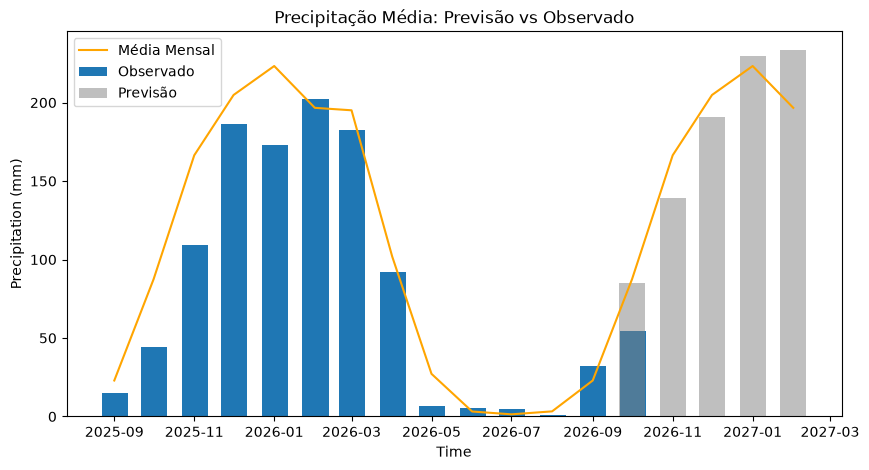

In [6]:
raw_rainfall_figure = inference.plot_raw_rainfall()

## Rainfall anomaly

Forecast/hindcast percentage anomaly for each model.

In [7]:
inference.plot_rainfall_anomaly().show()

## Corrected forecast rainfall

Corrected median rainfall and spread across models against observed rainfall and
climatology. The median rainfall defines one scenario; it is not a median discharge.

In [8]:
inference.plot_forecast_rainfall().show()

## Run CN3S

Both scenarios use the same saved historical rainfall prefix and calibrated initial
storage. Future rainfall follows either climatology or the corrected forecast median.
`inference.rain_scenarios` and `inference.discharge_scenarios` remain inspectable.
Monthly ACT shifts are already applied by CN3S; plotting alone moves markers to the 15th.

In [9]:
discharge = inference.run_model()
discharge.tail(len(inference.forecast_months) + inference.params.act)

,climatology,forecast
2026-10-01,2389.378065,2389.378065
2026-11-01,3883.911907,3772.254936
2026-12-01,7004.594307,5807.274054
2027-01-01,11458.008738,8437.624067
2027-02-01,16984.70364,12327.20527
2027-03-01,19025.09143,13463.328075


## Daily observations and discharge comparison

Retrieve the full daily discharge record online (Azure SQL sign-in required), then
plot the same historical references and 2024/2025/2026 overlays as notebook 04.
The monthly reference remains the median of pooled daily values; historical P10/P90
are not forecast uncertainty bounds. Online discharge is kept in memory.

In [10]:
observed_discharge = inference.load_discharge()

In [11]:
inference.plot_discharge().show()

## Monthly discharge comparison

Daily observations are averaged separately for each calendar month (m³/s). The
historical median and P10-P90 band are then calculated across those monthly means
for each calendar month, excluding the current reference month and later data.
These are historical variability bounds, not forecast uncertainty. Missing days
are not filled; means use available daily data and hover labels show the count.

The 13-month window places the month of `AS_OF_DATE` at its center. Current-month
observations are partial and shown separately from the full-month predictions.
Forecasts retain their model month labels and are not joined to daily endpoints.
The monthly observations and statistics remain available as
`inference.discharge_monthly` and `inference.discharge_monthly_stats`.

Month-only labels align the reference year (black) with the two previous years
(blue and green). Each year wraps by calendar month, with separate segments at
December/January; hover labels retain the source year. A thin gray dashed line
shows the historical median, and the reference line is labeled `MM/YYYY`.

In [20]:
monthly_discharge_figure = inference.plot_monthly_discharge(months_each_side=6)
monthly_discharge_figure.show()

In [ ]:
monthly_discharge_figure = inference.plot_monthly_discharge(
    months_each_side=6,
    anchor_to_observed=True,
)
monthly_discharge_figure.show()